# Resultados no teste final

Modelos, transformações e limiares já foram congelados na validação. As comparações abaixo não alteram a escolha. Este notebook também produz `ml/reports/RESULTADOS.md` com interpretação, erros e limitações.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml").is_dir() and (p / "sql").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from ml.data import load_tables
from ml.plotting import configure_style, style_table, save_figure
from ml.config import REPORTS, ARTIFACTS
get_ipython().run_line_magic("matplotlib", "inline")
configure_style()
pd.set_option("display.max_columns", 40)


In [2]:
from ml.experiment import evaluate_test
from ml.results import write_summary
test_metrics = evaluate_test()
summary_text = write_summary()
display(style_table(test_metrics[["modelo", "selecionado_na_validacao", "average_precision", "precision", "recall", "f1", "alertas", "fp", "fn"]].round(4)))


modelo,selecionado_na_validacao,average_precision,precision,recall,f1,alertas,fp,fn
Desvio historico,True,0.986400,0.991400,0.959800,0.975300,698,6,29
Isolation Forest,False,0.829600,0.891800,0.765600,0.823900,619,67,169
Autoencoder,False,0.351500,0.408400,0.364800,0.385300,644,381,458


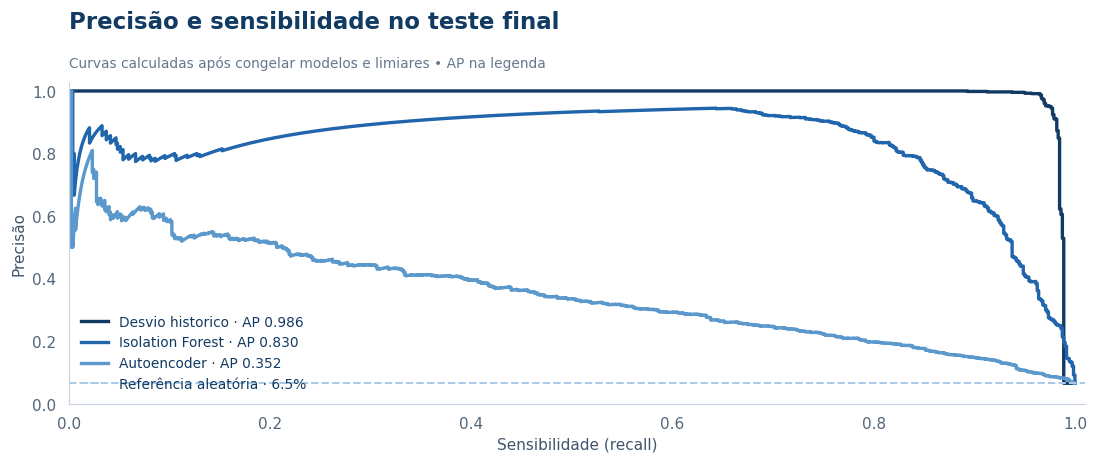

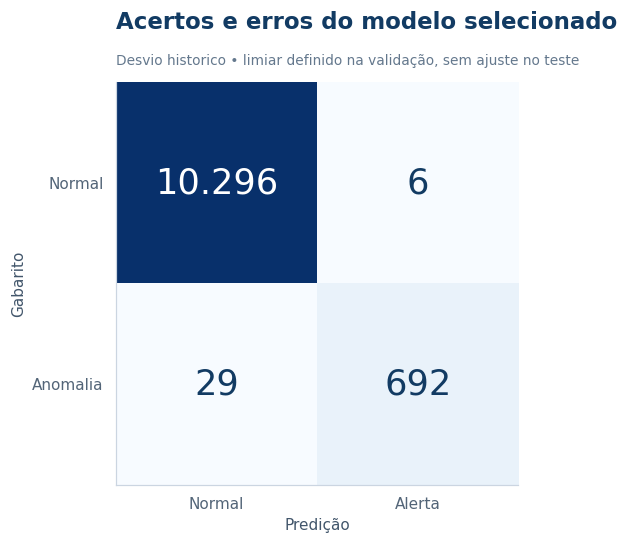

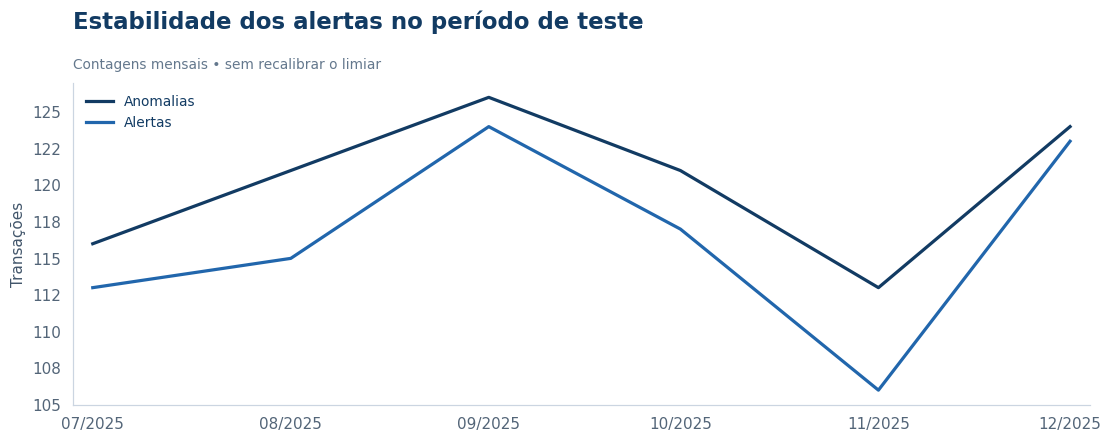

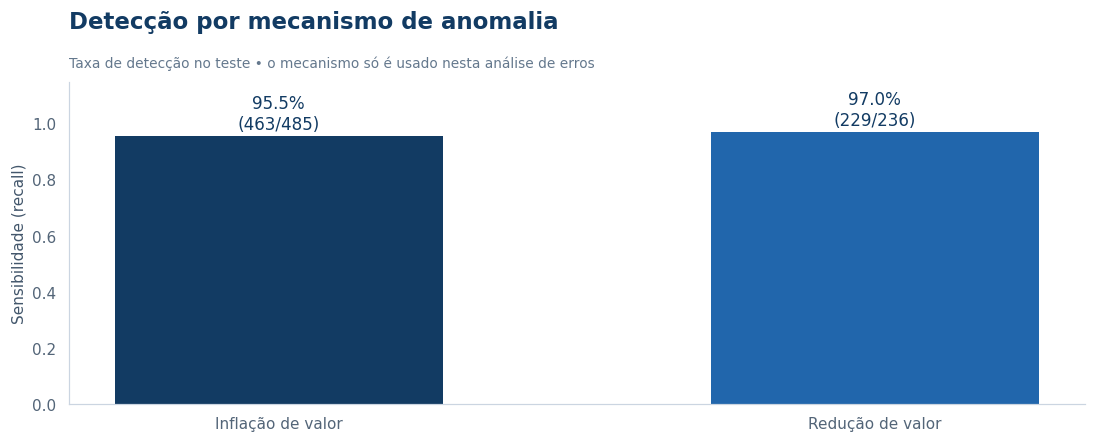

In [3]:
from ml.diagnostics import result_figures
figures = result_figures()
for figure in figures:
    display(figure)
    plt.close(figure)


## Incerteza das métricas

Bootstrap de 200 reamostragens de semanas inteiras do teste, mantendo os pesos e o limiar fixos. Os intervalos não incluem incerteza de seleção nem demonstram desempenho em dados reais.

In [4]:
display(style_table(pd.read_csv(REPORTS / "intervalos_bootstrap_semanal.csv").round(4)))


Unnamed: 0,limite_inferior_95,limite_superior_95
average_precision,0.978100,0.992800
f1,0.966200,0.982300
precision,0.984300,0.997200
recall,0.944400,0.971700


## Casos de erro

Os exemplos abaixo servem para compreender limitações. Ajustar o modelo com base nesses casos exigiria um novo teste independente.

In [5]:
errors = pd.read_csv(REPORTS / "casos_erro.csv")
display(style_table(errors[["id_transacao_natural", "data", "valor_bruto", "qtd_historico", "score", "tipo_anomalia", "erro"]].head(12).round(3)))


id_transacao_natural,data,valor_bruto,qtd_historico,score,tipo_anomalia,erro
TR-27006,2025-11-21,2289.420000,306,1.654000,inflacao,falso_negativo
TR-23356,2025-12-10,2070.790000,280,1.653000,inflacao,falso_negativo
TR-04105,2025-08-11,4703.060000,123,1.641000,reducao,falso_negativo
TR-08937,2025-08-08,1075.960000,227,1.631000,reducao,falso_negativo
TR-16817,2025-10-06,1959.380000,364,1.583000,reducao,falso_negativo
TR-32016,2025-08-22,2196.080000,146,1.483000,inflacao,falso_negativo
TR-29297,2025-10-13,9246.810000,80,1.459000,inflacao,falso_negativo
TR-30199,2025-07-28,6292.430000,25,1.397000,inflacao,falso_negativo
TR-02212,2025-10-09,4683.190000,281,1.375000,inflacao,falso_negativo
TR-05079,2025-12-08,3608.230000,209,1.375000,inflacao,falso_negativo


## Interpretação completa

In [6]:
display(Markdown(summary_text))

# Resultados — detecção de anomalias de valor

Modelo selecionado **antes de abrir o teste**: **Desvio historico**. Critério: maior Average Precision (AP) na validação.

## Protocolo

- Treino: 2024 (17.692 transações). Validação: janeiro–junho/2025 (11.077). Teste: julho–dezembro/2025 (11.023).
- Fit dos modelos e do pré-processamento apenas no treino, sem rótulos e sem remover anomalias conhecidas pelo gabarito.
- Contexto atualizado sequencialmente com dias anteriores, inclusive durante validação/teste; pesos dos modelos ficam congelados.
- Limiar de cada modelo escolhido pelo F1 na validação. Nenhum limiar ou modelo foi escolhido pelas métricas de teste.
- AP resume o ranking; precisão/recall/F1 usam o limiar fixado. Scores não são probabilidades de fraude.

## Comparação

| Modelo | AP validação | AP teste | Precisão teste | Recall teste | F1 teste |
|---|---:|---:|---:|---:|---:|
| Desvio historico | 0.9812 | 0.9864 | 99.14% | 95.98% | 0.9753 |
| Isolation Forest | 0.7956 | 0.8296 | 89.18% | 76.56% | 0.8239 |
| Autoencoder | 0.2944 | 0.3515 | 40.84% | 36.48% | 0.3853 |

## Modelo selecionado no teste

Foram identificadas **692 de 721 anomalias**, com **6 falsos positivos** e **29 falsos negativos**.
Taxa de alerta: **6.33%**. Prevalência de anomalias: **6.54%**.
Nos 5% maiores scores, precisão **100.00%** e recall **76.56%**.

Intervalo aproximado de 95% para AP: **[0.9781; 0.9928]**, bootstrap de 200 amostras por semana.
O intervalo é condicional aos pesos e ao limiar fixos; não mede a incerteza de todo o processo de seleção nem garante validade fora da simulação.

## Análise de erros

- Inflacao: 463/485 detectadas (recall 95.46%).
- Reducao: 229/236 detectadas (recall 97.03%).
- Parceiros/tipos sem histórico no dia: 27 transações, incluindo 2 anomalias. O baseline exige pelo menos cinco transações passadas e pode não alertar nesses casos.
- Os casos individuais estão em `casos_erro.csv`; mecanismos de injeção só aparecem na análise posterior, nunca nas features.

## Interpretação e limites

O baseline contextual superou a rede neural neste experimento. A injeção altera o valor por multiplicadores expressivos, enquanto o comportamento normal de cada parceiro é relativamente estável; comparar ao histórico é especialmente eficaz nesse cenário.
O autoencoder reconstrói a entrada e foi treinado com uma base contaminada. Um erro de reconstrução pequeno não garante ausência de anomalia. Esta comparação usa uma arquitetura fixa, sem busca extensiva de hiperparâmetros; não demonstra inferioridade geral de redes neurais.
Valores líquidos e descontos foram excluídos porque a injeção preserva o desconto absoluto original e pode deixar um atalho artificial. Status, liquidações, saldos, rating agregado, IDs de transação/parceiro, chaves técnicas e gabarito também não entram na matriz. Códigos de área e categoria entram como contexto categórico.
As anomalias são artificiais; não representam fraude comprovada ou risco de inadimplência. Uma única série sintética, uma seed e um corte temporal não demonstram generalização para empresas reais. A EDA descritiva inspeciona toda a base; o protocolo de teste não é um estudo confirmatório pré-registrado.

## Referências metodológicas

- [Isolation Forest — scikit-learn 1.3](https://scikit-learn.org/1.3/modules/generated/sklearn.ensemble.IsolationForest.html)
- [MLPRegressor — scikit-learn 1.3](https://scikit-learn.org/1.3/modules/generated/sklearn.neural_network.MLPRegressor.html)
- [Average Precision — scikit-learn 1.3](https://scikit-learn.org/1.3/modules/generated/sklearn.metrics.average_precision_score.html)
